In [16]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import numpy as np
import jinja2

In [17]:
AUTORES = ['Eduardo Ziegler Berti', 'Mateus Soares Lopes de Oliveira']

In [18]:
def carrega_tabela(database, tabela):
    '''
    Carrega uma tabela de um banco de dados 
    SQLite em um DataFrame do Pandas.
    Parâmetros:
    database: str - Caminho para o arquivo do banco de dados SQLite.
    tabela: str - Nome da tabela a ser carregada.
    '''
    with sqlite3.connect(database) as conn:
        query = f"SELECT * FROM {tabela}"
        df = pd.read_sql_query(query, conn)
    return df


In [19]:
def lista_tabelas(db_filename):
    '''
    Lista todas as tabelas em um banco de dados SQLite.
    Parâmetros:
    db_filename: str - Caminho para o arquivo do banco de dados SQLite.
    Retorna:
    DataFrame com os nomes das tabelas e suas contagens de linhas.
    '''
    conn = sqlite3.connect(db_filename)
    with sqlite3.connect(db_filename) as conn:
        cursor = conn.cursor()
        cursor.execute("SELECT name FROM sqlite_master WHERE type='table';")
        tables = cursor.fetchall()

        table_row_counts = []
        for table in tables:
            table_name = table[0]
            query = f"SELECT COUNT(*) FROM {table_name};"
            cursor.execute(query)
            row_count = cursor.fetchone()[0]
            table_row_counts.append({"Table": table_name, "Row_Count": row_count})

        return pd.DataFrame(table_row_counts)

# Tabela 1 - 20 Filmes com Maior Bilheteria e seu País de Origem

In [26]:
def tabela1():
    sessao = carrega_tabela('bilheteria.db', 'sessao')[['filme_id', 'publico']]
    filme = carrega_tabela('bilheteria.db', 'filme')[['id', 'titulo_original', 'pais_origem']]
    uniao = sessao.merge(filme, left_on='filme_id', right_on='id')
    soma = uniao.groupby(['titulo_original', 'pais_origem'])['publico'].sum().reset_index()
    tabela1 = soma.sort_values(by='publico', ascending=False).head(20).reset_index(drop=True)
    tabela1.index += 1
    tabela1 = tabela1.rename(columns={'titulo_original' : 'Título Original',
    'pais_origem' :'País de Origem',
    'publico' : 'Bilheteria'})
    return tabela1
tabela = tabela1()
print(tabela.to_latex())

\begin{tabular}{lllr}
\toprule
 & Título Original & País de Origem & Bilheteria \\
\midrule
1 & BARBIE & ESTADOS UNIDOS & 10238598 \\
2 & THE SUPER MARIO BROS. MOVIE & ESTADOS UNIDOS & 6235953 \\
3 & FAST X & ESTADOS UNIDOS & 6132354 \\
4 & AVATAR: THE WAY OF WATER & ESTADOS UNIDOS & 5631389 \\
5 & PUSS IN BOOTS: THE LAST WISH & ESTADOS UNIDOS & 5358525 \\
6 & GUARDIANS OF THE GALAXY VOL. 3 & ESTADOS UNIDOS & 4211764 \\
7 & THE LITTLE MERMAID & ESTADOS UNIDOS & 3987722 \\
8 & ELEMENTAL & ESTADOS UNIDOS & 3985017 \\
9 & SPIDER-MAN: ACROSS THE SPIDER-VERSE & ESTADOS UNIDOS & 3328797 \\
10 & THE NUN 2 & ESTADOS UNIDOS & 2839181 \\
11 & OPPENHEIMER & ESTADOS UNIDOS & 2808153 \\
12 & FIVE NIGHTS AT FREDDY'S & ESTADOS UNIDOS & 2777366 \\
13 & SOUND OF FREEDOM & ESTADOS UNIDOS & 2597889 \\
14 & ANT-MAN AND THE WASP: QUANTUMANIA & ESTADOS UNIDOS & 2588946 \\
15 & JOHN WICK: CHAPTER 4 & ESTADOS UNIDOS & 2303687 \\
16 & BLUE BEETLE & ESTADOS UNIDOS & 2015562 \\
17 & THE HUNGER GAMES – BALLAD OF 

# Tabela 2 - 20 Países com os Filmes de Maior Bilheteria

In [21]:
def tabela2():
    sessao = carrega_tabela('bilheteria.db', 'sessao')[['filme_id', 'publico']]
    filme = carrega_tabela('bilheteria.db', 'filme')[['id', 'pais_origem']]
    uniao = sessao.merge(filme, left_on='filme_id', right_on='id')
    soma = uniao.groupby([ 'pais_origem'])['publico'].sum().reset_index()
    tabela = soma.sort_values(by='publico', ascending=False).head(20).reset_index(drop=True)
    tabela.index += 1
    return tabela.rename(columns={'pais_origem' :'País de Origem',
    'publico' : 'Bilheteria'})

tabela_final = tabela2()
print(tabela_final.to_latex())


\begin{tabular}{llr}
\toprule
 & País de Origem & Bilheteria \\
\midrule
1 & ESTADOS UNIDOS & 99279694 \\
2 & CANADÁ & 3534725 \\
3 & BRASIL & 3138000 \\
4 & JAPÃO & 800298 \\
5 & INGLATERRA & 782284 \\
6 & AUSTRÁLIA & 780494 \\
7 & ESPANHA & 595599 \\
8 & ALEMANHA & 261791 \\
9 & FRANÇA & 235331 \\
10 & RÚSSIA & 129521 \\
11 & CHINA & 123470 \\
12 & REINO UNIDO & 111332 \\
13 & BELARUS (BIELORUSSIA) & 88021 \\
14 & REPÚBLICA TCHECA & 60417 \\
15 & BÉLGICA & 44085 \\
16 & CORÉIA DO SUL & 42468 \\
17 & REPÚBLICA DOMINICANA & 27248 \\
18 & PANAMÁ & 21056 \\
19 & ÍNDIA & 20848 \\
20 & CORÉIA DO NORTE & 12147 \\
\bottomrule
\end{tabular}



# Gráfico 1 - Soma das Bilheterias por Dia da Semana

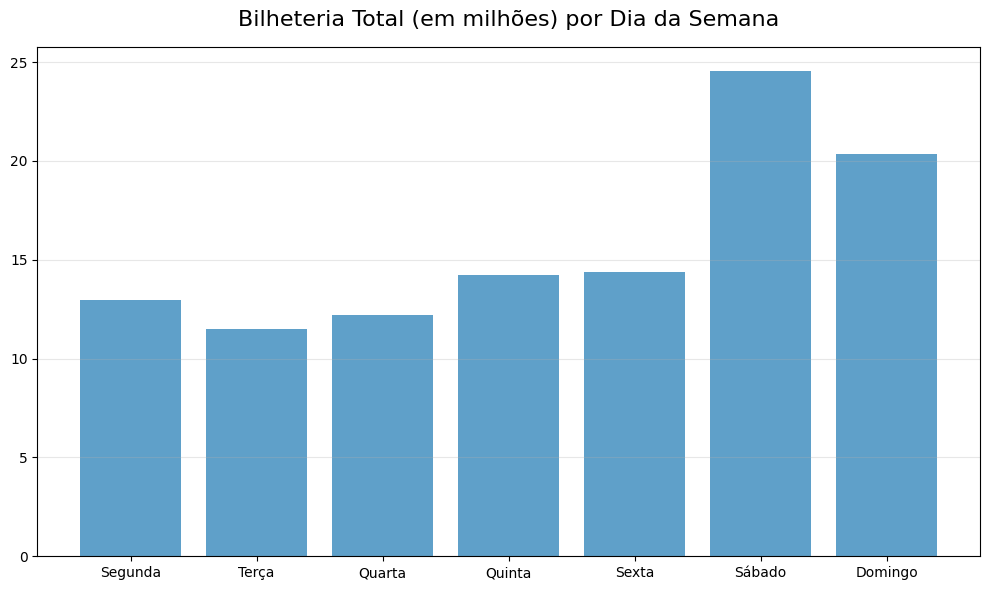

In [22]:
def grafico1():
    sessao = carrega_tabela('bilheteria.db', 'sessao')[['publico', 'data_exibicao']]
    sessao['data_exibicao'] = pd.to_datetime(sessao['data_exibicao'], format='%d/%m/%Y')
    dias = {
        0: 'Segunda',
        1: 'Terça',
        2: 'Quarta',
        3: 'Quinta',
        4: 'Sexta',
        5: 'Sábado',
        6: 'Domingo'
    }
    
    sessao['dia_semana'] = sessao['data_exibicao'].dt.dayofweek.map(dias)
    tabela = sessao.groupby('dia_semana')['publico'].sum().reindex(dias.values()).reset_index()

    plt.figure(figsize=(10, 6))
    plt.bar(tabela['dia_semana'], tabela['publico']/1000000, color='#5FA0C9')
    plt.title('Bilheteria Total (em milhões) por Dia da Semana', fontsize=16, pad=15)
    plt.grid(axis='y',alpha=0.3)
    plt.tight_layout()
    return plt.show()

grafico1()


# Gráfico 2 - Bilheteria por Mês

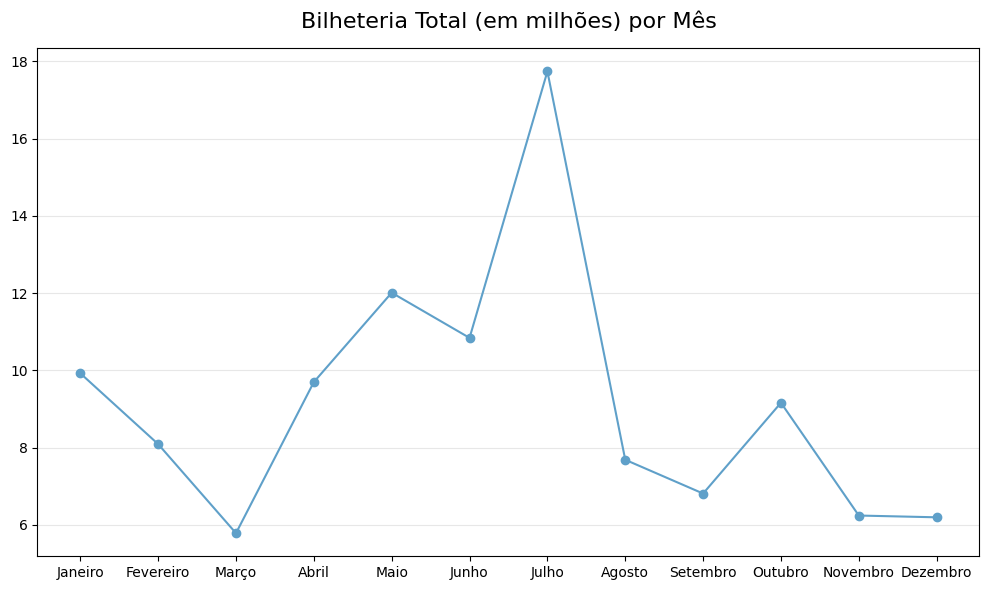

In [23]:
def grafico2():
    sessao = carrega_tabela('bilheteria.db', 'sessao')[['publico', 'data_exibicao']]
    sessao['data_exibicao'] = pd.to_datetime(sessao['data_exibicao'], format='%d/%m/%Y')
    meses = {
        1: 'Janeiro',
        2: 'Fevereiro',
        3: 'Março',
        4: 'Abril',
        5: 'Maio',
        6: 'Junho',
        7: 'Julho',
        8: 'Agosto',
        9: 'Setembro',
        10: 'Outubro',
        11: 'Novembro',
        12: 'Dezembro'
    }
    sessao['mes'] = sessao['data_exibicao'].dt.month.map(meses)
    tabela = sessao.groupby('mes')['publico'].sum().reindex(meses.values()).reset_index()

    plt.figure(figsize=(10, 6))
    plt.plot(tabela['mes'], tabela['publico']/1000000, color='#5FA0C9', marker='o')
    plt.title('Bilheteria Total (em milhões) por Mês', fontsize=16, pad=15)
    plt.grid(axis='y',alpha=0.3)
    plt.tight_layout()
    return plt.show()

grafico2()

# Gráfico 3 - Bilheteria Estrangeira x Bilheteria Nacional por Mês

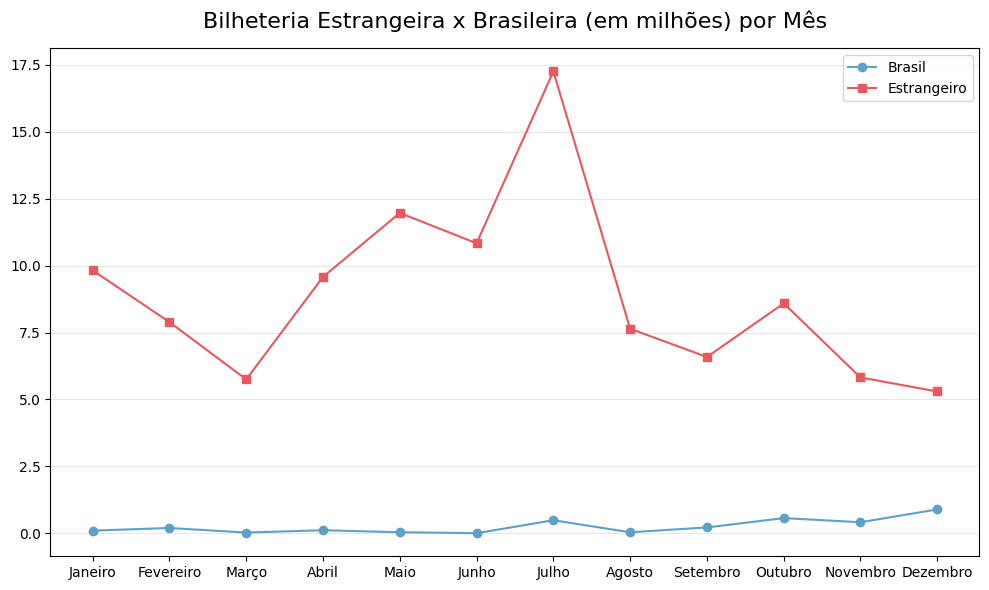

In [24]:
def grafico3():
    sessao = carrega_tabela('bilheteria.db', 'sessao')[['sala_id', 'publico', 'data_exibicao','filme_id']]
    sessao['data_exibicao'] = pd.to_datetime(sessao['data_exibicao'], format='%d/%m/%Y')
    filme = carrega_tabela('bilheteria.db', 'filme')[['id', 'pais_origem']]
    filme['pais_origem'] = np.where(filme['pais_origem'] == 'BRASIL', 'Brasil', 'Estrangeiro')
    tabela = sessao.merge(filme, left_on='filme_id', right_on='id')
    meses = {
        1: 'Janeiro',
        2: 'Fevereiro',
        3: 'Março',
        4: 'Abril',
        5: 'Maio',
        6: 'Junho',
        7: 'Julho',
        8: 'Agosto',
        9: 'Setembro',
        10: 'Outubro',
        11: 'Novembro',
        12: 'Dezembro'
    }
    tabela['mes'] = tabela['data_exibicao'].dt.month.map(meses)
    tabela = tabela.groupby(['mes', 'pais_origem'])['publico'].sum().reset_index()
    tabela['mes'] = pd.Categorical(tabela['mes'], categories=meses.values(), ordered=True)
    tabela = tabela.sort_values('mes')

    brasil = tabela[tabela['pais_origem'] == 'Brasil']
    estrangeiro = tabela[tabela['pais_origem'] == 'Estrangeiro']


    plt.figure(figsize=(10, 6))
    plt.plot(brasil['mes'], brasil['publico']/1000000, color='#5FA0C9', marker='o', label='Brasil')
    plt.plot(estrangeiro['mes'], estrangeiro['publico']/1000000, color='#E8585E', marker='s', label='Estrangeiro')
    plt.legend()
    plt.title('Bilheteria Estrangeira x Brasileira (em milhões) por Mês', fontsize=16, pad=15)
    plt.grid(axis='y',alpha=0.3)
    plt.tight_layout()
    return plt.show()

grafico3()

# Gráfico 4 - 10 Filmes Brasileiros com Maior Bilheteria

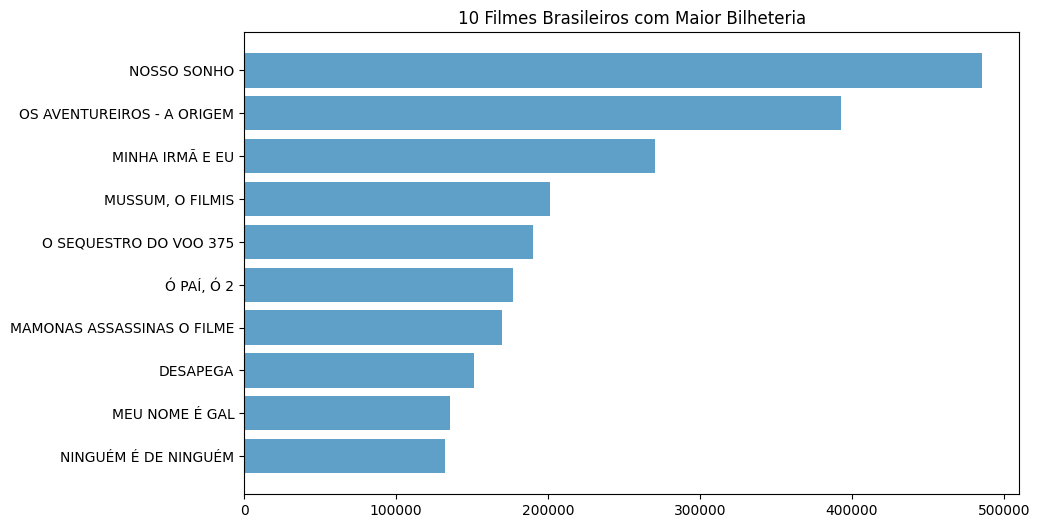

In [25]:
def grafico4():
    sessao = carrega_tabela('bilheteria.db', 'sessao')[['sala_id', 'publico','filme_id']]
    filme = carrega_tabela('bilheteria.db', 'filme')[['id', 'pais_origem', 'titulo_original']]
    filme['pais_origem'] = np.where(filme['pais_origem'] == 'BRASIL', 'Brasil', 'Estrangeiro')
    tabela = sessao.merge(filme, left_on='filme_id', right_on='id')
    filmes_brasileiros = tabela[tabela['pais_origem']=="Brasil"]
    filmes_mais_assistidos = filmes_brasileiros.groupby('titulo_original')['publico'].sum().sort_values(ascending=False)
    dez_filmes = filmes_mais_assistidos.head(10).reset_index()

    plt.figure(figsize=(10, 6))
    plt.title("10 Filmes Brasileiros com Maior Bilheteria")
    plt.barh(dez_filmes['titulo_original'],dez_filmes['publico'], color='#5FA0C9')
    plt.gca().invert_yaxis()
    plt.show()

grafico4()
    